# Homework 4 — Programming Exercises

**Applied Machine Learning | CS5785 / ORIE5750 / ECE5414 | Fall 2026**

The notebook contains the code, outputs, and discussion for both programming exercises. Outputs are saved in the notebook. To rerun, place this file inside the unzipped `hw4` folder alongside `faithful.dat` and `faces/`. The Python dependencies are NumPy, SciPy, Matplotlib, Pillow, scikit-learn, and threadpoolctl.

## 1. EM for Old Faithful

### 1(a) Load and plot the observations

I parsed all 272 observations as two-dimensional vectors with eruption duration first and time to the next eruption second. Both features are measured in minutes. The scatter plot shows groups broadly corresponding to short and long waiting times.

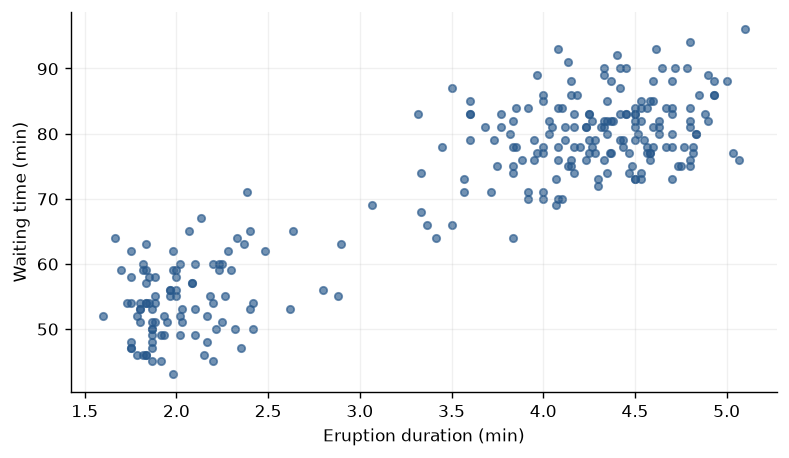

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from threadpoolctl import threadpool_limits

plt.rcParams.update({"figure.dpi": 125, "axes.spines.top": False, "axes.spines.right": False})
data_dir = Path.cwd()

lines = (data_dir / "faithful.dat").read_text().splitlines()
header = next(i for i, line in enumerate(lines) if line.split() == ["eruptions", "waiting"])
geyser = np.loadtxt(lines[header + 1:], usecols=(1, 2))
assert geyser.shape == (272, 2)

def geyser_axes(ax):
    ax.set(xlabel="Eruption duration (min)", ylabel="Waiting time (min)")
    ax.grid(alpha=0.18)

fig, ax = plt.subplots(figsize=(6.2, 3.55), layout="constrained")
ax.scatter(*geyser.T, s=18, alpha=0.65, color="#27588b")
geyser_axes(ax)
plt.show()

### 1(b) E-step

At iteration $t$, component $k$ has mixing weight $\phi_k^{(t)}$, mean $\mu_k^{(t)}$, and covariance $\Sigma_k^{(t)}$. By Bayes' rule, the responsibility of component $k$ for observation $x_i$ is

$$
\gamma_{ik}^{(t)}
= P(z_i = k \mid x_i, \theta^{(t)})
= \frac{
\phi_k^{(t)} \mathcal{N}(x_i \mid \mu_k^{(t)}, \Sigma_k^{(t)})
}{
\sum_{\ell=1}^{2} \phi_{\ell}^{(t)}
\mathcal{N}(x_i \mid \mu_{\ell}^{(t)}, \Sigma_{\ell}^{(t)})
}.
$$

For each observation, the two responsibilities sum to one.

### 1(c) M-step

Let $N_k = \sum_{i=1}^{n} \gamma_{ik}^{(t)}$ be the effective number of observations assigned to component $k$. With the responsibilities fixed, the updated weight and mean are

$$
\phi_k^{(t+1)} = \frac{N_k}{n},
\qquad
\mu_k^{(t+1)} = \frac{1}{N_k}\sum_{i=1}^{n} \gamma_{ik}^{(t)} x_i.
$$

The updated covariance is

$$
\Sigma_k^{(t+1)}
= \frac{1}{N_k}\sum_{i=1}^{n} \gamma_{ik}^{(t)}
(x_i-\mu_k^{(t+1)})(x_i-\mu_k^{(t+1)})^{T}.
$$

For the diagonal covariance model, I keep the diagonal entries and set any variance below $10^{-6}$ to $10^{-6}$ to avoid singular covariances.

### 1(d) Implement EM, check convergence, and plot the mean trajectories

I initialized the means at two observations selected without replacement with random seed 4. I set both mixing weights to 0.5 and initialized each diagonal covariance with the two global feature variances. The E-step uses log-sum-exp for stable normalization.

I stopped when the absolute change in the observed-data log-likelihood was at most $10^{-6}$, with a cap of 500 updates. Log-likelihood measures progress on the fitted objective directly. In the plot, open circles mark the initial means and stars mark the final means.

EM updates: 10
Log-likelihood: -1587.238762 → -1147.806353
Last improvement: 3.04e-07
Component 1: weight=0.64348, mean=[ 4.29107 79.98563], diagonal variance=[ 0.16815 35.7733 ]
Component 2: weight=0.35652, mean=[ 2.03792 54.49296], diagonal variance=[ 0.07034 33.75588]


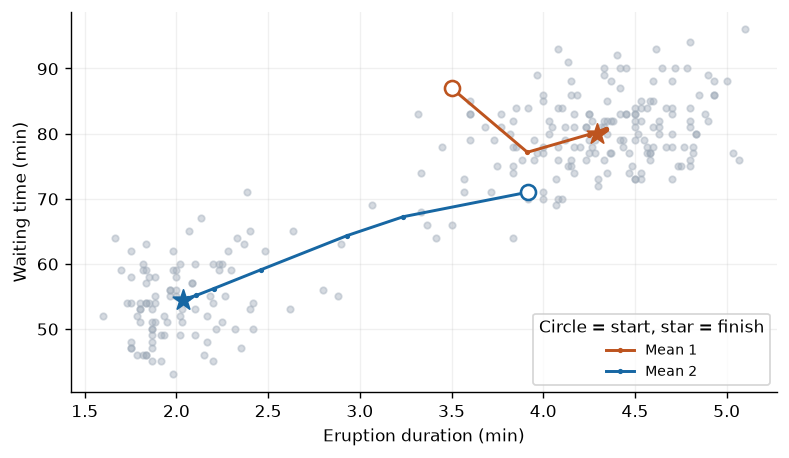

In [2]:
def expectation(data, weights, means, variances):
    squared_distance = (data[:, None, :] - means[None, :, :]) ** 2
    log_density = -0.5 * np.sum(
        np.log(2 * np.pi * variances) + squared_distance / variances, axis=2
    )
    log_joint = log_density + np.log(weights)
    log_marginal = logsumexp(log_joint, axis=1, keepdims=True)
    return np.exp(log_joint - log_marginal), float(log_marginal.sum())


def maximization(data, responsibilities, variance_floor=1e-6):
    counts = responsibilities.sum(axis=0)
    weights = counts / len(data)
    means = (responsibilities.T @ data) / counts[:, None]
    squared_distance = (data[:, None, :] - means[None, :, :]) ** 2
    variances = np.einsum("nk,nkd->kd", responsibilities, squared_distance)
    return weights, means, np.maximum(variances / counts[:, None], variance_floor)


def fit_em(data, seed=4, tolerance=1e-6, max_iter=500):
    rng = np.random.default_rng(seed)
    means = data[rng.choice(len(data), size=2, replace=False)].copy()
    weights = np.full(2, 0.5)
    variances = np.tile(data.var(axis=0), (2, 1))
    mean_path = [means.copy()]
    responsibilities, likelihood = expectation(data, weights, means, variances)
    history = [likelihood]

    for _ in range(max_iter):
        weights, means, variances = maximization(data, responsibilities)
        responsibilities, likelihood = expectation(data, weights, means, variances)
        improvement = likelihood - history[-1]
        mean_path.append(means.copy())
        history.append(likelihood)
        if abs(improvement) <= tolerance:
            break
    else:
        raise RuntimeError("EM reached its iteration limit before converging")

    return weights, means, variances, responsibilities, np.array(mean_path), np.array(history)


weights, means, variances, responsibilities, mean_path, history = fit_em(geyser)
assert np.allclose(responsibilities.sum(axis=1), 1)
assert np.all(np.diff(history) >= -1e-8)
assert np.isclose(weights.sum(), 1)
print(f"EM updates: {len(history) - 1}")
print(f"Log-likelihood: {history[0]:.6f} → {history[-1]:.6f}")
print(f"Last improvement: {history[-1] - history[-2]:.3g}")
for k in range(2):
    print(f"Component {k + 1}: weight={weights[k]:.5f}, mean={means[k].round(5)}, "
          f"diagonal variance={variances[k].round(5)}")

fig, ax = plt.subplots(figsize=(6.2, 3.55), layout="constrained")
ax.scatter(*geyser.T, color="#9da9b7", alpha=0.42, s=14)
for k, color in enumerate(("#bd541f", "#1767a3")):
    path = mean_path[:, k, :]
    ax.plot(*path.T, ".-", color=color, linewidth=1.7, markersize=4, label=f"Mean {k + 1}")
    ax.scatter(*path[0], facecolors="white", edgecolors=color, s=75, linewidths=1.5, zorder=4)
    ax.scatter(*path[-1], marker="*", color=color, s=150, zorder=5)
geyser_axes(ax)
ax.legend(loc="lower right", title="Circle = start, star = finish", fontsize=8)
plt.show()

EM stopped after 10 updates. The log-likelihood rose from −1587.2388 to −1147.8064. The final means were approximately (4.29, 79.99) and (2.04, 54.49) minutes in (duration, waiting time) coordinates.

### 1(e) Compare with K-means

I fit K-means with $K=2$ on the same unscaled features. For the comparison, I labeled the clusters in each fit by their mean waiting times and gave each GMM point the label with the largest posterior probability. The rings in the plots mark points assigned differently.

Rows: EM short/long. Columns: K-means short/long.
[[ 96   1]
 [  4 171]]
Agreement: 267/272. Adjusted Rand index: 0.92717
Disagreement points [eruption duration, waiting time]:
[[ 3.367 66.   ]
 [ 3.833 64.   ]
 [ 3.5   66.   ]
 [ 2.383 71.   ]
 [ 3.417 64.   ]]


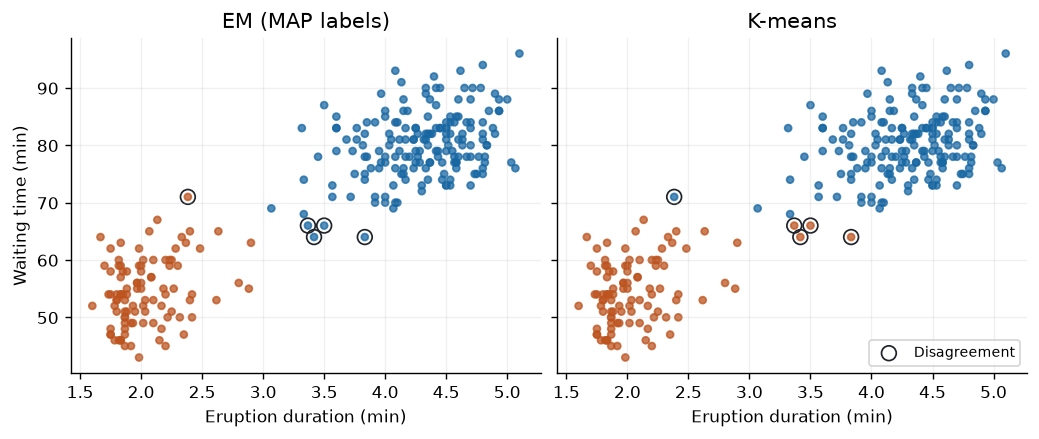

In [3]:
with threadpool_limits(limits=1):
    kmeans = KMeans(n_clusters=2, n_init=20, random_state=4).fit(geyser)

em_label = np.argsort(means[:, 1]).argsort()[responsibilities.argmax(axis=1)]
km_label = np.argsort(kmeans.cluster_centers_[:, 1]).argsort()[kmeans.labels_]
different = em_label != km_label
contingency = np.zeros((2, 2), dtype=int)
np.add.at(contingency, (em_label, km_label), 1)
ari = adjusted_rand_score(em_label, km_label)
print("Rows: EM short/long. Columns: K-means short/long.")
print(contingency)
print(f"Agreement: {(~different).sum()}/{len(geyser)}. Adjusted Rand index: {ari:.5f}")
print("Disagreement points [eruption duration, waiting time]:")
print(geyser[different])

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.4), sharex=True, sharey=True, layout="constrained")
for ax, labels, title in zip(axes, (em_label, km_label), ("EM (MAP labels)", "K-means")):
    ax.scatter(*geyser.T, c=np.array(["#bd541f", "#1767a3"])[labels], s=16, alpha=0.75)
    ax.scatter(*geyser[different].T, facecolors="none", edgecolors="#20242a", s=72,
               linewidths=1, label="Disagreement")
    geyser_axes(ax)
    ax.set_title(title)
axes[1].set_ylabel("")
axes[1].legend(loc="lower right", fontsize=8)
plt.show()

The fits agreed on **267 of 272** observations, with an adjusted Rand index of **0.927**. The groups are largely separated. Waiting time has a larger numeric range than eruption duration, so it dominates the unscaled Euclidean distances used by K-means. The GMM also uses component-specific variances and mixing weights, which changes a few assignments near the boundary.

## 2. Eigenfaces for face recognition

### 2(a) Load the course dataset

I extracted the course's Yale Face Database B archive and used `train.txt` and `test.txt` to preserve the supplied split.

### 2(b) Build and inspect the image matrices

Each grayscale image is $50\times50$ pixels. I flattened each image in row-major order, producing a $540\times2500$ training matrix and a $100\times2500$ test matrix. The first two panels display one unmodified image from each split.

### 2(c) Compute the average face

I computed the pixelwise mean $mu$ using only the 540 training images. The center panel displays this average.

### 2(d) Subtract the mean face

I subtracted the same training mean $mu$ from every training and test image. The last two panels show the centered examples with a shared grayscale range centered at zero.

Train: (540, 2500) Test: (100, 2500)


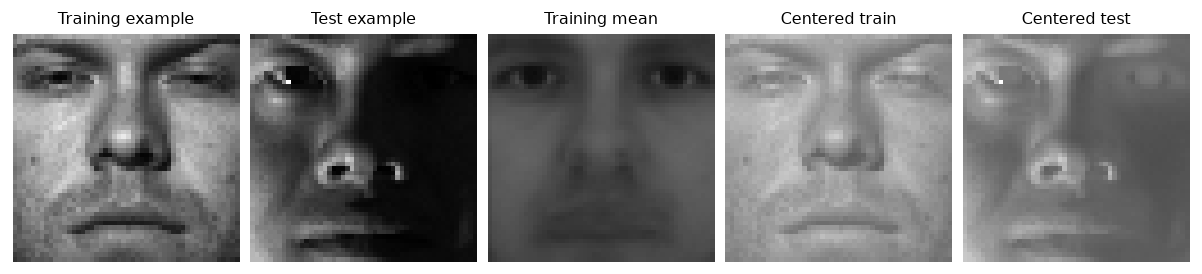

In [4]:
def load_faces(split):
    vectors, labels = [], []
    for line in (data_dir / "faces" / f"{split}.txt").read_text().splitlines():
        relative_path, label = line.split()
        with Image.open(data_dir / relative_path) as image:
            pixels = np.asarray(image.convert("L"), dtype=np.float64)
            assert pixels.shape == (50, 50), relative_path
            vectors.append(pixels.ravel())
        labels.append(int(label))
    return np.stack(vectors), np.array(labels)


X, y = load_faces("train")
X_test, y_test = load_faces("test")
assert X.shape == (540, 2500) and X_test.shape == (100, 2500)
assert len(np.unique(y)) == 10
mean_face = X.mean(axis=0)
X_centered = X - mean_face
X_test_centered = X_test - mean_face
print("Train:", X.shape, "Test:", X_test.shape)

signed_limit = max(np.abs(X_centered[10]).max(), np.abs(X_test_centered[10]).max())
fig, axes = plt.subplots(1, 5, figsize=(9.5, 2.15), layout="constrained")
examples = [
    ("Training example", X[10]), ("Test example", X_test[10]),
    ("Training mean", mean_face), ("Centered train", X_centered[10]),
    ("Centered test", X_test_centered[10]),
]
for i, (ax, (title, vector)) in enumerate(zip(axes, examples)):
    limits = (0, 255) if i < 3 else (-signed_limit, signed_limit)
    ax.imshow(vector.reshape(50, 50), cmap="gray", vmin=limits[0], vmax=limits[1])
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.show()

### 2(e) Compute and display the first ten eigenfaces

Taking the economy SVD of the centered training matrix gives $X_c=U S V^\top$, so $X_c^\top X_c=V S^2 V^\top$ using the singular values on the diagonal of $S$. The first ten rows of $V^\top$ therefore give the ten leading eigenfaces. Each eigenface is reshaped to $50\times50$ for display.

### 2(f) Generate the $r$-dimensional features

The function `eigenface_features` computes $F = X_c V_r$ and $F_{\text{test}} = X_{\text{test},c} V_r$ using the same leading $r$ eigenvectors for both splits. Here $V_r$ comprises the first $r$ columns of $V$. The output shapes are $540\times r$ and $100\times r$.

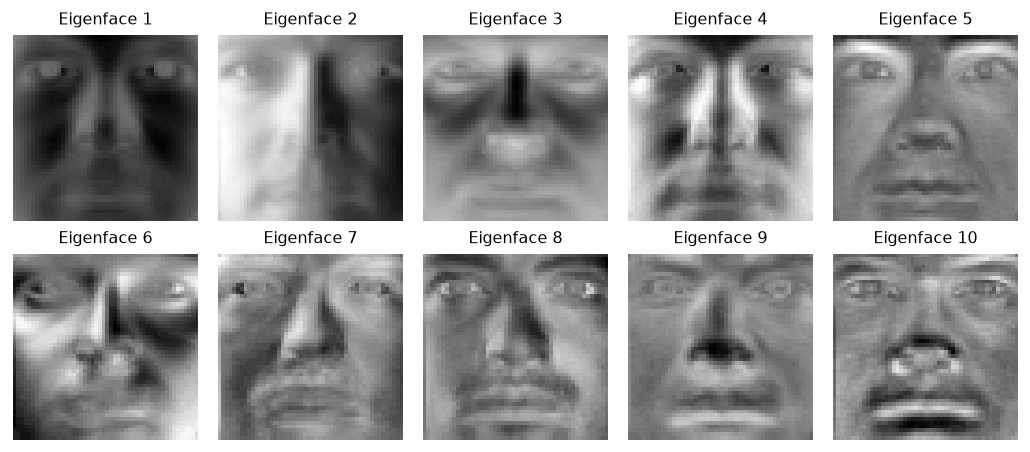

In [5]:
with threadpool_limits(limits=1):
    _, singular_values, Vt = np.linalg.svd(X_centered, full_matrices=False)

def eigenface_features(centered_data, components, r):
    return centered_data @ components[:r].T


fig, axes = plt.subplots(2, 5, figsize=(8.2, 3.5), layout="constrained")
for i, ax in enumerate(axes.ravel()):
    vector = Vt[i].reshape(50, 50)
    limit = np.abs(vector).max()
    ax.imshow(vector, cmap="gray", vmin=-limit, vmax=limit)
    ax.set_title(f"Eigenface {i + 1}", fontsize=9)
    ax.axis("off")
plt.show()

### 2(g) Train one-vs-rest logistic regression and plot test accuracy

For every integer $r$ from 1 through 200, I trained ten independent binary logistic regressions, one for each subject versus the other nine. I used L2 regularization with $C=1$ and divided the projected scores by 255 in both splits. The predicted identity was the subject with the highest classifier score.

Test accuracy at r=10: 79.0%
Highest test accuracy: 99.0%, first reached at r=49
Selected ranks: {1: 0.14, 5: 0.41, 10: 0.79, 20: 0.88, 50: 0.99, 100: 0.97, 150: 0.99, 200: 0.99}


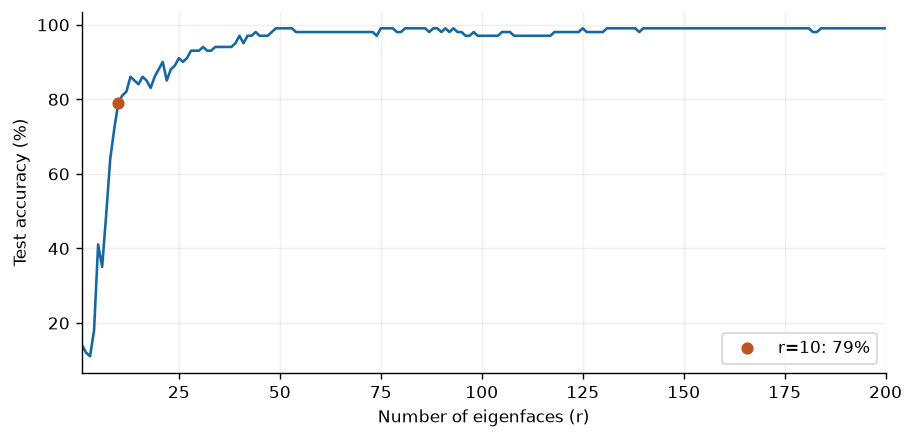

In [6]:
with threadpool_limits(limits=1):
    train_features = eigenface_features(X_centered, Vt, 200) / 255.0
    test_features = eigenface_features(X_test_centered, Vt, 200) / 255.0
    ranks = np.arange(1, 201)
    accuracy = np.empty(len(ranks))
    for i, r in enumerate(ranks):
        model = OneVsRestClassifier(
            LogisticRegression(solver="liblinear", C=1.0, max_iter=2000, random_state=4)
        )
        model.fit(train_features[:, :r], y)
        accuracy[i] = model.score(test_features[:, :r], y_test)

best_ranks = ranks[accuracy == accuracy.max()]
print(f"Test accuracy at r=10: {accuracy[9]:.1%}")
print(f"Highest test accuracy: {accuracy.max():.1%}, first reached at r={best_ranks[0]}")
print("Selected ranks:", {int(r): round(float(accuracy[r - 1]), 3)
                          for r in (1, 5, 10, 20, 50, 100, 150, 200)})

fig, ax = plt.subplots(figsize=(7.2, 3.4), layout="constrained")
ax.plot(ranks, 100 * accuracy, color="#1767a3", linewidth=1.5)
ax.scatter(10, 100 * accuracy[9], color="#bd541f", zorder=3, label=f"r=10: {accuracy[9]:.0%}")
ax.set(xlabel="Number of eigenfaces (r)", ylabel="Test accuracy (%)", xlim=(1, 200))
ax.grid(alpha=0.2)
ax.legend(loc="lower right")
plt.show()

At the requested **$r=10$**, the classifier correctly identified **79 of 100 test images (79%)**. The accuracy was 14% at $r=1$ and 88% at $r=20$. The sweep first reached 99% at $r=49$. These percentages describe the supplied test split. A separate validation split would be needed to select $r$ and leave the test set for an independent evaluation.

### Data sources

- [Old Faithful Geyser Data](https://www.stat.cmu.edu/~larry/all-of-statistics/=data/faithful.dat)
- [Yale Face Database B course archive](https://cornelltech.github.io/cs5785-fall-2019/data/faces.zip)